# 🔥 Depth3D Localizer — Interactive Demo

**Primary model**: DepthART (Depth Anything Rethought for Tiny Models) — ACM Multimedia 2026

Workflow:
1. Tải ảnh hoặc video frame
2. **DepthART** ước lượng bản đồ chiều sâu (affine-invariant relative depth)
3. **Click chuột** vào bất kỳ điểm nào → trả về tọa độ 3D
4. Tích hợp với FireBase-YOLO26: nhập `(kx, ky)` từ keypoint BASE để định vị lửa

### Setup DepthART (chạy 1 lần trước khi dùng notebook):
```bash
python install_depthart.py
```
---

In [4]:
# ── Cell 1: Import & Setup ──────────────────────────────────────────────────
import sys
from pathlib import Path

MODULE_DIR = Path(".").resolve()
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))

import numpy as np
import cv2
from PIL import Image
import json
import matplotlib
import matplotlib.pyplot as plt

from depth_model import DepthBackend
from localizer_3d import FireLocalizer3D, CameraIntrinsics

print("✅ Import thành công!")

✅ Import thành công!


In [5]:
# ── Cell 2: Khởi tạo DepthART backend ──────────────────────────────────────
#
# === CHỌN BACKEND ===
# prefer='depthart'  → DepthART (PRIMARY) — cần chạy install_depthart.py trước
#   encoder=None       → tự chọn: MNV4-S (CPU) hoặc TinyViM-S (GPU)
#   encoder='MNV4-S'   → MobileNetV4-S, chạy CPU, ~11M params, KHÔNG cần CUDA ext
#   encoder='MNV4-M'   → MobileNetV4-M, CPU ok
#   encoder='S'        → TinyViM-S, GPU only, cần Selective Scan CUDA extension
#   encoder='B','L'    → TinyViM B/L, GPU only
# prefer='auto'      → DepthART first, fallback DAv2 nếu repo chưa cài
# prefer='dav2'      → Depth Anything V2 Small (không cần DepthART setup)

backend = DepthBackend(
    prefer='depthart',           # ← DepthART là PRIMARY
    depthart_encoder=None,       # None = tự chọn encoder phù hợp theo device
    # depthart_encoder='MNV4-S', # ← chỉ định CPU-friendly MobileNetV4-S
    # depthart_encoder='S',      # ← TinyViM-S (GPU only)
)

# Nếu chưa chạy install_depthart.py → đổi prefer='auto' để fallback về DAv2
backend.load()

localizer = FireLocalizer3D(
    near_thresh=0.70,   # depth_norm > 0.7 → NEAR (gần camera)
    far_thresh=0.30,    # depth_norm < 0.3 → FAR  (xa camera)
    patch_radius=3,
)

print(f"=== Backend: {backend.model_name} ===")
print(f"Device: {backend.device}")

[DepthBackend] Loaded: DepthART-MNV4-S @ 224px  [CPU]  (cpu)
=== Backend: DepthART-MNV4-S @ 224px  [CPU] ===
Device: cpu


In [6]:
# ── Cell 3: Tải ảnh & chạy depth estimation ─────────────────────────────────
IMAGE_PATH = "../../datasets/fire-samples/dataset_test_default_img_102.jpg"   # ← Thay bằng đường dẫn ảnh của bạn, vd: "fire_sample.jpg"

if not IMAGE_PATH or not Path(IMAGE_PATH).exists():
    print("⚠️  Không tìm thấy ảnh → dùng ảnh gradient demo.")
    print("   Sửa IMAGE_PATH bên trên để dùng ảnh thật.")
    demo_img = np.zeros((480, 640, 3), dtype=np.uint8)
    for i in range(480):
        demo_img[i, :] = [int(i/480*180), int(50+i/480*100), int(200-i/480*150)]
    cv2.putText(demo_img, "DEMO - Replace with real fire image",
                (60, 240), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,0), 2)
    pil_image = Image.fromarray(demo_img)
else:
    pil_image = Image.open(IMAGE_PATH).convert("RGB")
    print(f"✅ Đã tải: {IMAGE_PATH} ({pil_image.size})")

W, H = pil_image.size

print(f"🔄 Đang chạy DepthART inference...")
depth_map = backend.infer_pil(pil_image)
depth_colored = backend.colorize(depth_map)
depth_colored_rgb = cv2.cvtColor(depth_colored, cv2.COLOR_BGR2RGB)
print(f"✅ Depth map: {depth_map.shape}, range=[{depth_map.min():.4f}, {depth_map.max():.4f}]")

✅ Đã tải: ../../datasets/fire-samples/dataset_test_default_img_102.jpg ((224, 224))
🔄 Đang chạy DepthART inference...
✅ Depth map: (224, 224), range=[1174.3013, 12816.1484]


In [7]:
# ── Cell 4: Interactive Click Demo ──────────────────────────────────────────
# Click vào ảnh trái → hiện tọa độ 3D + zone (NEAR/MID/FAR)
%matplotlib tk
# Nếu TkAgg lỗi → thử: %matplotlib qt5

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    f"Depth3D Localizer [{backend.model_name}] — Click vào ảnh để lấy tọa độ 3D",
    fontsize=12, fontweight="bold"
)

ax_img = axes[0]
ax_dep = axes[1]

ax_img.imshow(np.array(pil_image))
ax_img.set_title("Ảnh gốc — Click để chọn điểm", fontsize=11)
ax_img.axis("off")

ax_dep.imshow(depth_colored_rgb)
ax_dep.set_title("Depth Map\n🟡 Vàng=Gần  |  🟣 Tím=Xa", fontsize=11)
ax_dep.axis("off")

info_box = fig.text(
    0.01, 0.02,
    "👆 Click vào ảnh bên trái để xem tọa độ 3D...",
    fontsize=9, verticalalignment="bottom", family="monospace",
    bbox=dict(boxstyle="round", facecolor="#1a1a2e", alpha=0.85, edgecolor="#e94560"),
    color="#e0e0e0",
)

markers = []

def on_click(event):
    if event.inaxes != ax_img or event.xdata is None:
        return
    kx, ky = int(event.xdata), int(event.ydata)

    loc = localizer.localize(depth_map, kx, ky, img_w=W, img_h=H,
                             model_name=backend.model_name)

    for m in markers:
        try: m.remove()
        except: pass
    markers.clear()

    zone_colors = {"NEAR": "#ff4444", "MID": "#ffaa00", "FAR": "#44ff44"}
    mc = zone_colors.get(loc.zone, "white")

    m1, = ax_img.plot(kx, ky, "o", color=mc, markersize=12,
                      markeredgewidth=2.5, markeredgecolor="white", zorder=5)
    m2 = ax_img.annotate(
        f"{loc.zone}\n({kx},{ky})",
        xy=(kx, ky), xytext=(kx+15, ky-20),
        fontsize=8, color="white", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.3", fc=mc, alpha=0.85),
        arrowprops=dict(arrowstyle="->", color=mc),
    )
    dH, dW = depth_map.shape
    m3, = ax_dep.plot(int(kx*dW/W), int(ky*dH/H), "x", color=mc,
                      markersize=14, markeredgewidth=3, zorder=5)
    markers.extend([m1, m2, m3])

    xn, yn, zn = loc.xyz_normalized
    zone_em = {"NEAR": "🔴", "MID": "🟡", "FAR": "🟢"}.get(loc.zone, "⚪")
    info_box.set_text(
        f"Pixel     : ({kx:4d}, {ky:4d})\n"
        f"Depth raw : {loc.depth_value:.4f}   norm: {loc.depth_normalized:.3f}\n"
        f"Depth pct : {loc.depth_percentile:.1f}% scene xa hon diem nay\n"
        f"Zone      : {zone_em} {loc.zone}\n"
        f"XYZ norm  : X={xn:+.4f}  Y={yn:+.4f}  Z={zn:.4f}\n"
        f"Model     : {backend.model_name}"
    )
    fig.canvas.draw_idle()

fig.canvas.mpl_connect("button_press_event", on_click)
plt.tight_layout(rect=[0, 0.13, 1, 1])
plt.show()
print("✅ Cửa sổ đã mở. Click vào ảnh bên trái để xem tọa độ 3D.")

✅ Cửa sổ đã mở. Click vào ảnh bên trái để xem tọa độ 3D.


C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_31960\895431814.py:76: UserWarning: Glyph 128993 (\N{LARGE YELLOW CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0.13, 1, 1])
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_31960\895431814.py:76: UserWarning: Glyph 128995 (\N{LARGE PURPLE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0.13, 1, 1])


In [8]:
# ── Cell 5: Non-interactive — input keypoints từ FireBase-YOLO26 ─────────────
# Nhập trực tiếp keypoints (kx, ky) BASE từ output của FireBase-YOLO26

firebase_keypoints = [
    (320, 350),   # (kx, ky) — điểm tiếp đất lửa 1
    (150, 400),   # điểm tiếp đất lửa 2
]

print(f"📍 Localize {len(firebase_keypoints)} keypoint(s) từ FireBase-YOLO26:\n")

results = []
for kx, ky in firebase_keypoints:
    loc = localizer.localize(depth_map, kx, ky, img_w=W, img_h=H,
                             model_name=backend.model_name)
    results.append(loc)
    print(loc)
    print()

print("\n📦 JSON output:")
print(json.dumps([r.to_dict() for r in results], indent=2, ensure_ascii=False))

📍 Localize 2 keypoint(s) từ FireBase-YOLO26:

🔥 FireBase 3D Location @ pixel(320, 350)
   Depth  : 6220.4019 (raw)  →  normalized 0.433
   Zone   : 🟡 MID  (sâu hơn 80.7% scene)
   XYZ(n) : (+1.8571, +2.1250, 0.5666)  — relative position feature
   XYZ(m) : Not available (cần metric depth model)

🔥 FireBase 3D Location @ pixel(150, 400)
   Depth  : 6329.9854 (raw)  →  normalized 0.443
   Zone   : 🟡 MID  (sâu hơn 82.3% scene)
   XYZ(n) : (+0.3393, +2.5714, 0.5571)  — relative position feature
   XYZ(m) : Not available (cần metric depth model)


📦 JSON output:
[
  {
    "pixel": {
      "x": 320,
      "y": 350
    },
    "depth_value": 6220.40185546875,
    "depth_normalized": 0.43344501204387487,
    "depth_percentile": 80.65609056122449,
    "xyz_normalized": [
      1.8571428571428572,
      2.125,
      0.5665549879561251
    ],
    "xyz_metric": null,
    "relative_distance": 0.5665549879561251,
    "zone": "MID",
    "model_name": "DepthART-MNV4-S @ 224px  [CPU]",
    "metadata": {

C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_31960\3861626665.py:42: UserWarning: Glyph 128993 (\N{LARGE YELLOW CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_31960\3861626665.py:42: UserWarning: Glyph 128995 (\N{LARGE PURPLE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_31960\3861626665.py:43: UserWarning: Glyph 128993 (\N{LARGE YELLOW CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig("depth3d_result.png", dpi=120, bbox_inches="tight",
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_31960\3861626665.py:43: UserWarning: Glyph 128995 (\N{LARGE PURPLE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.savefig("depth3d_result.png", dpi=120, bbox_inches="tight",
C:\Users\ThinkPad\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128993 (\N{LARGE YELLOW CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.pr

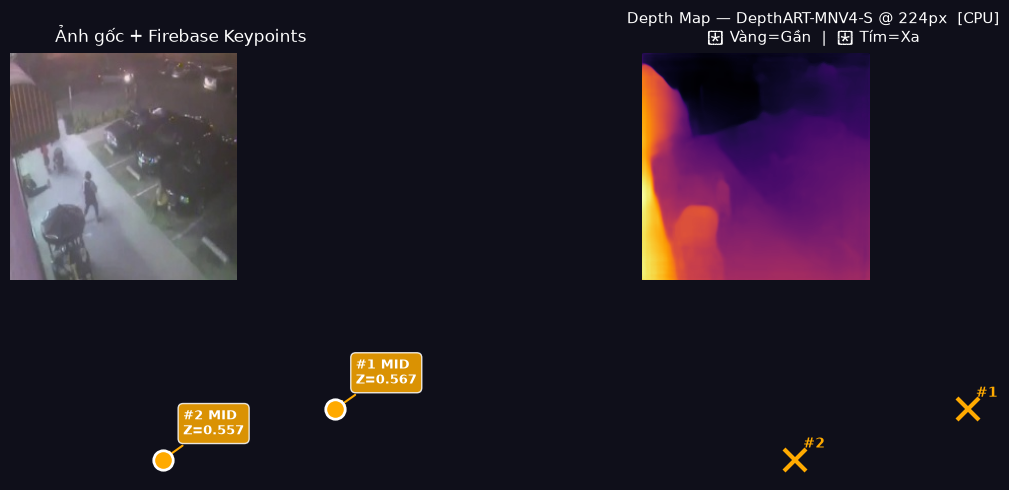

✅ Đã lưu: depth3d_result.png


In [9]:
# ── Cell 6: Static visualization (Kaggle/Colab friendly) ─────────────────────
%matplotlib inline

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)
fig.patch.set_facecolor("#0f0f1a")

for ax in axes:
    ax.set_facecolor("#1a1a2e")

axes[0].imshow(np.array(pil_image))
axes[0].set_title(f"Ảnh gốc + Firebase Keypoints", color="white", fontsize=12, pad=8)
axes[0].axis("off")

zone_colors = {"NEAR": "#ff4444", "MID": "#ffaa00", "FAR": "#44dd44"}
for i, loc in enumerate(results):
    c = zone_colors.get(loc.zone, "white")
    axes[0].plot(loc.pixel_x, loc.pixel_y, "o", color=c, markersize=14,
                 markeredgewidth=2, markeredgecolor="white", zorder=5)
    axes[0].annotate(
        f"#{i+1} {loc.zone}\nZ={loc.xyz_normalized[2]:.3f}",
        xy=(loc.pixel_x, loc.pixel_y), xytext=(loc.pixel_x+20, loc.pixel_y-25),
        fontsize=9, color="white", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.4", fc=c, alpha=0.85, ec="white"),
        arrowprops=dict(arrowstyle="->", color=c, lw=1.5),
    )

axes[1].imshow(depth_colored_rgb)
axes[1].set_title(f"Depth Map — {backend.model_name}\n🟡 Vàng=Gần  |  🟣 Tím=Xa",
                  color="white", fontsize=11, pad=8)
axes[1].axis("off")

dH, dW = depth_map.shape
for i, loc in enumerate(results):
    c = zone_colors.get(loc.zone, "white")
    axes[1].plot(int(loc.pixel_x*dW/W), int(loc.pixel_y*dH/H),
                 "x", color=c, markersize=16, markeredgewidth=3, zorder=5)
    axes[1].annotate(f"#{i+1}",
                     xy=(int(loc.pixel_x*dW/W), int(loc.pixel_y*dH/H)),
                     xytext=(int(loc.pixel_x*dW/W)+8, int(loc.pixel_y*dH/H)-12),
                     fontsize=10, color=c, fontweight="bold")

plt.tight_layout()
plt.savefig("depth3d_result.png", dpi=120, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()
print("✅ Đã lưu: depth3d_result.png")

In [10]:
# ── Cell 7: Video Processing với DepthART ────────────────────────────────────
VIDEO_PATH = ""   # ← Đường dẫn video .mp4 / .avi
PROCESS_EVERY_N = 5
MAX_FRAMES = 30

if not VIDEO_PATH or not Path(VIDEO_PATH).exists():
    print("⚠️  Không tìm thấy video. Sửa VIDEO_PATH để thử.")
else:
    cap = cv2.VideoCapture(VIDEO_PATH)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    vw = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    vh = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    print(f"📹 {vw}x{vh} @ {fps:.1f} FPS — Model: {backend.model_name}")

    frame_idx = 0
    processed = 0
    while cap.isOpened() and processed < MAX_FRAMES:
        ret, frame = cap.read()
        if not ret: break
        frame_idx += 1
        if frame_idx % PROCESS_EVERY_N != 0: continue

        depth_f = backend.infer_bgr(frame)
        processed += 1
        print(f"  Frame {frame_idx:4d}: depth=[{depth_f.min():.3f}, {depth_f.max():.3f}]")

    cap.release()
    print(f"✅ Đã xử lý {processed} frames.")

⚠️  Không tìm thấy video. Sửa VIDEO_PATH để thử.


In [ ]:
# ── Cell 8: Full pipeline — YOLO26 + DepthART + 3D Localize ──────────────────

def full_pipeline(
    image_path: str,
    yolo_weights: str = None,
    conf: float = 0.20,
):
    """
    Pipeline đầy đủ:
    FireBase-YOLO26 (kx,ky) → DepthART depth → FireLocalizer3D (X,Y,Z)
    """
    pil_img = Image.open(image_path).convert("RGB")
    W, H = pil_img.size

    # Step 1: FireBase-YOLO26 keypoints
    keypoints = []
    if yolo_weights and Path(yolo_weights).exists():
        from ultralytics import YOLO
        m = YOLO(yolo_weights)
        bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)
        res = m.predict(bgr, conf=conf, verbose=False)[0]
        if res.keypoints is not None:
            for kpts in res.keypoints.xy.cpu().numpy():
                if len(kpts) > 0:
                    keypoints.append((int(kpts[0][0]), int(kpts[0][1])))
        print(f"🔥 YOLO26: {len(keypoints)} điểm lửa")
    else:
        keypoints = [(W//2, int(H*0.75))]  # mock
        print("⚠️  Mock keypoint (không có YOLO weights)")

    # Step 2: DepthART depth
    depth = backend.infer_pil(pil_img)

    # Step 3: 3D Localize
    locs = localizer.localize_batch(depth, keypoints, img_w=W, img_h=H,
                                    model_name=backend.model_name)
    for i, loc in enumerate(locs):
        print(f"\n{'='*50}\n🔥 Lửa #{i+1}:\n{loc}")
    return locs


# Bỏ comment để chạy:
# full_pipeline(
#     image_path="path/to/fire.jpg",
#     yolo_weights="../FireBase_YOLO26/training_runs/firebase_yolo26n/weights/best.pt",
# )
print("💡 Bỏ comment và sửa đường dẫn để chạy full pipeline YOLO26 + DepthART.")